In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/glassdoor_jobs.csv")
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


In [3]:
## Data Cleaning: Salary Estimate- cleaning the salary estimate column. Splitting the salary estimate column into min and max salary columns.And Casting the min and max salary columns to int type. 

In [4]:
(df == -1).sum()

Unnamed: 0            0
Job Title             0
Salary Estimate       0
Job Description       0
Rating               34
Company Name          0
Location              0
Headquarters          0
Size                  0
Founded              97
Type of ownership     0
Industry              0
Sector                0
Revenue               0
Competitors           0
dtype: int64

In [5]:
df['Salary Estimate'] = df['Salary Estimate'].str.replace(r'[^\d\-]', '', regex=True)

In [6]:
(df['Salary Estimate'] == '-1').sum()

np.int64(214)

In [7]:
import numpy as np


In [8]:
df['Salary Estimate'] = df['Salary Estimate'].replace('-1', np.nan)

In [9]:
df[['Min Salary', 'Max Salary']] = df['Salary Estimate'].str.split('-', n=1, expand=True)

In [10]:
df['Min Salary'] = pd.to_numeric(df['Min Salary'])
df['Max Salary'] = pd.to_numeric(df['Max Salary'])

In [11]:
df[['Salary Estimate', 'Min Salary', 'Max Salary']].head(10)



,Salary Estimate,Min Salary,Max Salary
0,53-91,53.0,91.0
1,63-112,63.0,112.0
2,80-90,80.0,90.0
3,56-97,56.0,97.0
4,86-143,86.0,143.0
5,71-119,71.0,119.0
6,54-93,54.0,93.0
7,86-142,86.0,142.0
8,38-84,38.0,84.0
9,120-160,120.0,160.0


In [12]:
df['Min Salary'].isnull().sum()

np.int64(214)

## Data Cleaning: Company Name- cleaning the Company Name column. Removed dulpicate columns.

In [13]:
df['Company Name'] = df['Company Name'].str.split('\n').str[0]

In [14]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

In [15]:
df.duplicated().sum()

np.int64(356)

In [16]:
df = df.drop_duplicates()

In [17]:
df = df.reset_index(drop=True)

## Data Cleaning: Location- cleaning the Location column. Extracting the state from the Location column and creating a new column called 'Job State'.

In [18]:
df['Location'].str.split(', ').str[-1].value_counts()


Location
CA               135
MA                73
NY                60
VA                39
IL                27
MD                24
TX                23
PA                23
WA                18
NJ                17
FL                12
NC                11
DC                10
AZ                 9
OH                 9
GA                 9
UT                 9
TN                 9
CO                 8
MO                 8
MI                 7
AL                 7
IN                 7
WI                 5
MN                 4
NE                 4
KY                 3
OR                 3
LA                 3
IA                 3
NM                 2
CT                 2
RI                 2
Virginia           2
DE                 2
ID                 2
Oregon             1
New Jersey         1
AK                 1
United States      1
SC                 1
KS                 1
PR                 1
Maryland           1
Michigan           1
Name: count, dtype: int64

In [19]:
no_comma = df[~df['Location'].str.contains(',', na=False)]['Location'].unique()
print("\nLocations without a comma:", no_comma)


Locations without a comma: <StringArray>
['Oregon', 'New Jersey', 'Virginia', 'United States', 'Maryland', 'Michigan']
Length: 6, dtype: str


In [20]:
multi_comma = df[df['Location'].str.count(',') > 1]['Location'].unique()
print("\nLocations with multiple commas:", multi_comma)


Locations with multiple commas: <StringArray>
['Santa Fe Springs, Los Angeles, CA']
Length: 1, dtype: str


In [21]:
df['Job State'] = df['Location'].str.split(',').str[-1].str.strip()

In [22]:
state_fix = {
    'Oregon': 'OR',
    'New Jersey': 'NJ',
    'Virginia': 'VA',
    'Maryland': 'MD',
    'Michigan': 'MI',
    'United States': np.nan
}

In [23]:
df['Job State'] = df['Job State'].replace(state_fix)

## Verification

In [24]:
bad_states = df[df['Job State'].str.len() != 2]['Job State'].unique()
print("State with not equal to 2 characters:", bad_states)

State with not equal to 2 characters: [nan]


In [25]:
df['Job State'].isnull().sum()

np.int64(1)

## Data Cleaning: Headquarters- cleaning the Headquarters column.

In [26]:
df['Headquarters'].isnull().sum()

np.int64(0)

In [27]:
(df['Headquarters'] == '-1').sum()

np.int64(7)

In [28]:
df[~df['Headquarters'].str.contains(',',na=False)]['Headquarters'].unique()

<StringArray>
['-1']
Length: 1, dtype: str

In [29]:
hq_split = df['Headquarters'].replace('-1', np.nan).str.split(',').str[-1].str.strip()

In [30]:
weird_hq = hq_split[hq_split.str.len() != 2].unique()
print("HQ values not equal to 2 characters:", weird_hq)

HQ values not equal to 2 characters: ['Japan' 'Switzerland' 'Germany' 'United Kingdom' 'Belgium' 'China'
 'Bermuda' 'South Korea' 'India' 'Singapore' nan 'Spain' 'France']


In [31]:
numeric_hq = hq_split[hq_split.str.contains(r'\d', na=False)].unique()
print("HQ values with numbers:", numeric_hq)

HQ values with numbers: []


In [32]:
df['HQ State'] = df['Headquarters'].replace('-1', np.nan).str.split(',').str[-1].str.strip()

In [33]:
df['Same State'] = (df['Job State'] == df['HQ State']).astype(int)

## Verification

In [34]:
(df['HQ State'].isnull().sum())

np.int64(7)

In [35]:
print("\nJobs at HQ State vs Different State (1 = Same, 0 = Different):")
print(df['Same State'].value_counts())


Jobs at HQ State vs Different State (1 = Same, 0 = Different):
Same State
1    391
0    209
Name: count, dtype: int64


## Data Cleaning : Rating and Founded - cleaning the rating and founded columns.

In [36]:
(df[['Rating', 'Founded']].info())

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Rating   600 non-null    float64
 1   Founded  600 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 9.5 KB


In [37]:
(df[['Rating', 'Founded']] == -1).sum()

Rating     21
Founded    62
dtype: int64

In [38]:
df[df['Rating'] != -1]['Rating'].min(), df['Rating'].max()

(np.float64(1.9), np.float64(5.0))

In [39]:
df[df['Founded'] != -1]['Founded'].min(), df['Founded'].max()

(np.int64(1744), np.int64(2019))

In [40]:
df[['Rating', 'Founded']] = df[['Rating', 'Founded']].replace(-1, np.nan)

In [41]:
df['Company Age'] = 2026 - df['Founded']

## Data Cleaning: Cleaning Size, Type of ownership, Industry, Sector, Revenue. 

In [42]:
cat_cols = ['Size', 'Type of ownership', 'Industry', 'Sector', 'Revenue']
(df[cat_cols] == '-1').sum()

Size                  7
Type of ownership     7
Industry             24
Sector               24
Revenue               7
dtype: int64

In [43]:
df[cat_cols].isnull().sum()

Size                 0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
dtype: int64

In [44]:
df[cat_cols].apply(lambda col: col.str.contains('Unknown', case=False, na=False)).sum() 

Size                   9
Type of ownership      6
Industry               0
Sector                 0
Revenue              191
dtype: int64

In [45]:
df['Size'].unique()

<StringArray>
[  '501 to 1000 employees',        '10000+ employees',
  '1001 to 5000 employees',     '51 to 200 employees',
    '201 to 500 employees', '5001 to 10000 employees',
       '1 to 50 employees',                 'Unknown',
                      '-1']
Length: 9, dtype: str

In [46]:
df['Type of ownership'].unique()

<StringArray>
[             'Company - Private',             'Other Organization',
                     'Government',               'Company - Public',
                       'Hospital', 'Subsidiary or Business Segment',
         'Nonprofit Organization',                       'Contract',
                        'Unknown',           'College / University',
        'Private Practice / Firm',                             '-1',
       'School / School District']
Length: 13, dtype: str

In [47]:
df['Revenue'].unique()

<StringArray>
[       '$50 to $100 million (USD)',           '$2 to $5 billion (USD)',
       '$100 to $500 million (USD)', '$500 million to $1 billion (USD)',
         'Unknown / Non-Applicable',           '$1 to $2 billion (USD)',
         '$25 to $50 million (USD)',               '$10+ billion (USD)',
           '$1 to $5 million (USD)',         '$10 to $25 million (USD)',
          '$5 to $10 billion (USD)',       'Less than $1 million (USD)',
          '$5 to $10 million (USD)',                               '-1']
Length: 14, dtype: str

In [48]:
df[cat_cols] = df[cat_cols].replace('-1', np.nan)

In [49]:
df[cat_cols] = df[cat_cols].replace(['Unknown', 'Unknown / Non-Applicable'], np.nan)

In [50]:
df[cat_cols].isnull().sum()

Size                  16
Type of ownership     13
Industry              24
Sector                24
Revenue              198
dtype: int64

In [51]:
(df[cat_cols] == '-1').sum()

Size                 0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
dtype: int64

In [52]:
df[cat_cols].apply(lambda col: col.str.contains('Unknown', case=False, na=False)).sum()

Size                 0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
dtype: int64

In [53]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Min Salary', 'Max Salary', 'Job State', 'HQ State', 'Same State',
       'Company Age'],
      dtype='str')

In [54]:
(df['Competitors'] == '-1').sum()

np.int64(394)

In [55]:
df['Competitors'] = df['Competitors'].replace('-1', np.nan)

In [56]:
df['Competitors'].head(5)

0                                                  NaN
1                                                  NaN
2                                                  NaN
3    Oak Ridge National Laboratory, National Renewa...
4                 Commerce Signals, Cardlytics, Yodlee
Name: Competitors, dtype: str

In [57]:
df['Headquarters'] = df['Headquarters'].replace('-1', np.nan)

In [58]:
((df == '-1').sum().sum())

np.int64(0)

In [59]:
df['Avg Salary'] = (df['Min Salary'] + df['Max Salary'])/2

In [60]:
(df['Avg Salary'].isnull().sum())

np.int64(133)

In [61]:
df['Avg Salary'].describe()

count    467.000000
mean     100.978587
std       37.318755
min       13.500000
25%       76.000000
50%       97.500000
75%      121.000000
max      254.000000
Name: Avg Salary, dtype: float64

In [62]:
df.to_csv("../data/glassdoor_jobs_cleaned.csv", index=False)

## Group by Job State, with Average Salary and Job Count

In [63]:
State_Salary = (
    df.groupby('Job State')['Avg Salary']
    .agg(Job_Count='count', Mean_Salary='mean')
    .query('Job_Count >= 5')
    .sort_values(by='Mean_Salary', ascending=False)
    .round(1)
    .head(10)
)
print('Top 10 highest paying states (Min. 5 job posting):')
print(State_Salary)

Top 10 highest paying states (Min. 5 job posting):
           Job_Count  Mean_Salary
Job State                        
CA                99        124.4
IL                22        112.3
DC                 9        110.2
MA                60        104.8
NJ                13        102.3
NY                47        100.2
NC                11         99.2
MD                22         99.0
VA                30         97.7
PA                19         92.3


## Aggrigation: Job count, min, average, and max salary. Quick categorization of Job Titles.

In [64]:
df['Role Category'] = 'other'
df.loc[df['Job Title'].str.contains('data scientist|data science', case=False, na=False), 'Role Category'] = 'Data Scientist'
df.loc[df['Job Title'].str.contains('data engineer', case=False, na=False), 'Role Category'] = 'Data Engineer'
df.loc[df['Job Title'].str.contains('analyst', case=False, na=False), 'Role Category'] = 'Data Analyst'


In [65]:
role_summery = (
    df.groupby('Role Category')['Avg Salary']
    .agg(Total_Jobs='count', Avg_Salary_K='mean', Min_Salary_K='min', Max_Salary_K='max')
    .sort_values('Avg_Salary_K', ascending=False)
    .round(1)
)
print(role_summery)

                Total_Jobs  Avg_Salary_K  Min_Salary_K  Max_Salary_K
Role Category                                                       
Data Scientist         210         116.6          15.5         254.0
Data Engineer           74         103.5          60.5         205.0
other                  111          91.2          20.0         232.5
Data Analyst            72          68.1          13.5         173.0


## Which Industry Sectors Are Hiring the Most.

In [66]:
Sector_Analysis = (
    df.groupby('Sector')['Avg Salary']
    .agg(Job_Postings='count', Avg_Salary_K='mean')
    .sort_values(by='Job_Postings', ascending=False)
    .round(1)
    .head(10)
)
print("Top 10 hiring sectors & their average salary ($K):")
print(Sector_Analysis)

Top 10 hiring sectors & their average salary ($K):
                           Job_Postings  Avg_Salary_K
Sector                                               
Information Technology              124         110.5
Business Services                    70          95.5
Biotech & Pharmaceuticals            62         113.4
Insurance                            41         101.8
Health Care                          25          77.7
Finance                              25          98.1
Aerospace & Defense                  20          99.3
Manufacturing                        18          86.2
Education                            14         102.5
Retail                                8         104.8


## Does Working at Company Headquarters or a Higher-Rated Company Pay More?

In [67]:
hq_pay = df.groupby('Same State')['Avg Salary'].agg(Count='count', Avg_Salary_K='mean').round(1)
print("Salary by HQ Location (1 = Same State as HQ, 0 = Different State ):")
print(hq_pay)

print("\nCorrelation matrix:")
print(df[['Avg Salary', 'Rating', 'Company Age']].corr().round(3))

Salary by HQ Location (1 = Same State as HQ, 0 = Different State ):
            Count  Avg_Salary_K
Same State                     
0             154         101.7
1             313         100.6

Correlation matrix:
             Avg Salary  Rating  Company Age
Avg Salary        1.000   0.115        0.008
Rating            0.115   1.000       -0.192
Company Age       0.008  -0.192        1.000


In [68]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

# Plot histogram of Avg Salary.Vertical dashed red line for the overall mean salary.

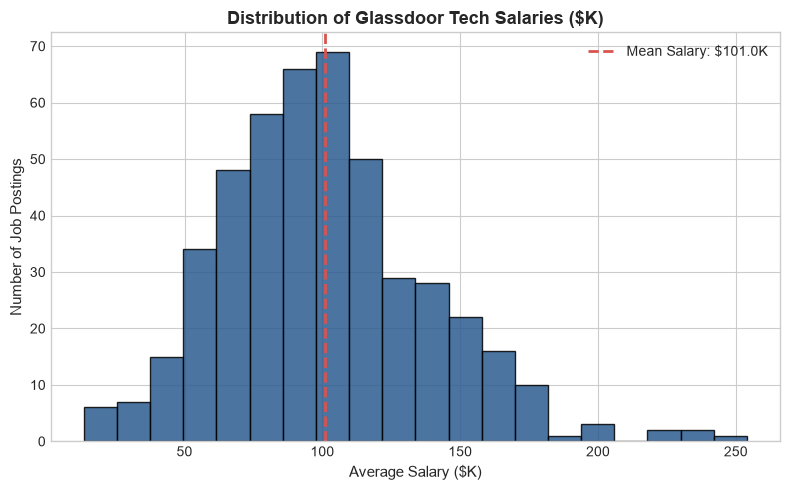

In [70]:
plt.figure(figsize=(8, 5))

plt.hist(df['Avg Salary'].dropna(), bins=20, color='#2b5c8f', edgecolor='black', alpha=0.85)

mean_sal = df['Avg Salary'].mean()
plt.axvline(mean_sal, color='#d9534f', linestyle='--', linewidth=2, label=f'Mean Salary: ${mean_sal:.1f}K')

plt.title('Distribution of Glassdoor Tech Salaries ($K)', fontsize=13, fontweight='bold')
plt.xlabel('Average Salary ($K)', fontsize=11)
plt.ylabel('Number of Job Postings', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## Top 10 Highest Paying States.

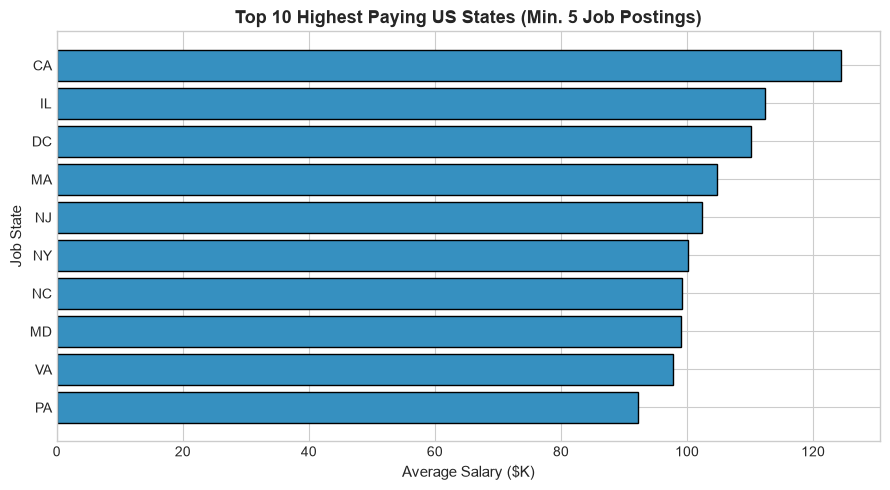

In [71]:
plt.figure(figsize=(9, 5))

state_plot = State_Salary.sort_values(by='Mean_Salary', ascending=True)

plt.barh(state_plot.index, state_plot['Mean_Salary'], color='#3690c0', edgecolor='black')

plt.title('Top 10 Highest Paying US States (Min. 5 Job Postings)', fontsize=13, fontweight='bold')
plt.xlabel('Average Salary ($K)', fontsize=11)
plt.ylabel('Job State', fontsize=11)
plt.tight_layout()
plt.show()

## Average Salary by Core Data Role

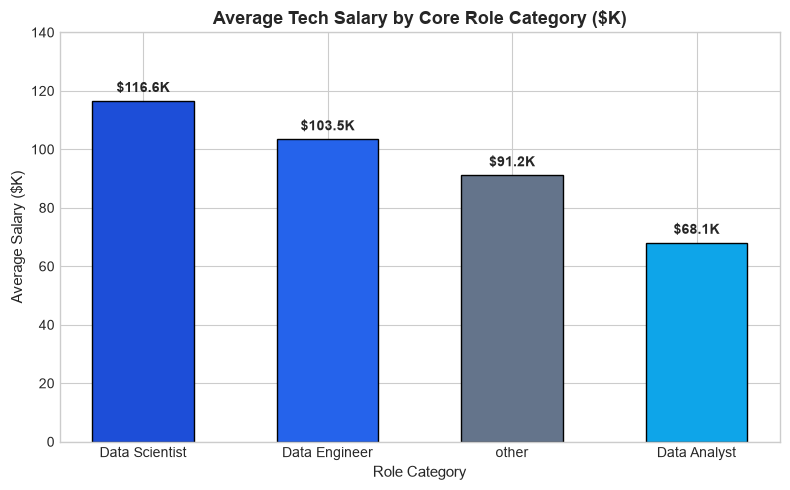

In [72]:
plt.figure(figsize=(8, 5))

plt.bar(role_summery.index, role_summery['Avg_Salary_K'], color=['#1d4ed8', '#2563eb', '#64748b', '#0ea5e9'], edgecolor='black', width=0.55)

plt.title('Average Tech Salary by Core Role Category ($K)', fontsize=13, fontweight='bold')
plt.xlabel('Role Category', fontsize=11)
plt.ylabel('Average Salary ($K)', fontsize=11)
plt.ylim(0, 140)

for i, val in enumerate(role_summery['Avg_Salary_K']):
    plt.text(i, val + 3, f'${val}K', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()